# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/')
#sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [10]:
SRC = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/md_istarwell2_100M'
n_frames = 1_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 1000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

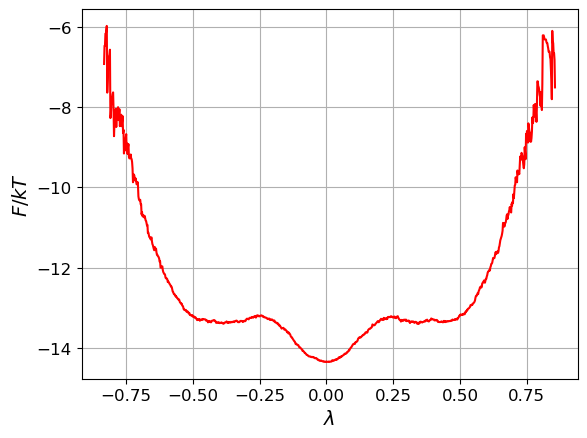

In [11]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [12]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are shown here and saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed.

**Warm-up (optional):** the first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV choice (`WARMUP_CV`: `None` random, `0` λ only, `1` v only); then `ENVELOPE` and `GAMMA` take over. The seed matters through the first CVs drawn: in a test with seeds 0–3, the one run that drew v first (seed 1) reached the exact committor (RMS 0.019) and the three that drew λ first kept sharp edges at λ ≈ ±0.29 (RMS 0.052 for seed 0). `WARMUP_CV = 1` with a short warm-up tests this. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1 | Random seeds |
| `MAX_ITER` | 15000 | Iterations per seed after the warm-up |
| `CHUNK` | 5000 | Iterations between shown and saved plots |
| `ENVELOPE` | 1 | RC envelope width (`envelope_scale`) |
| `GAMMA` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `WARMUP_ITER` | 0 | Warm-up iterations (0 = off) |
| `WARMUP_ENVELOPE`, `WARMUP_GAMMA`, `WARMUP_CV` | 1, 0.1, None | Warm-up settings |
| `ny` | 6 | Polynomial degree |

#=1000, xent=0.395396, mse=0.13856, sdzq=44.5454, dzq=252.548, dr2=1643.03, auc=0.874005, |dx|=0.190234, time=4.0447
--- figures/langevin_seeds/seed99, warmup1000 ---


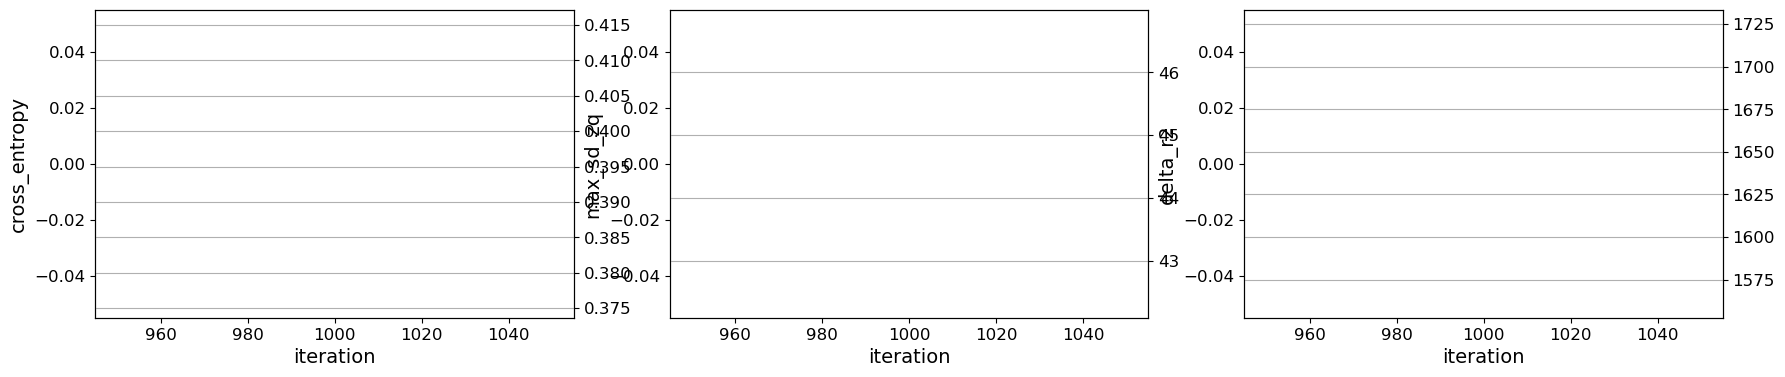

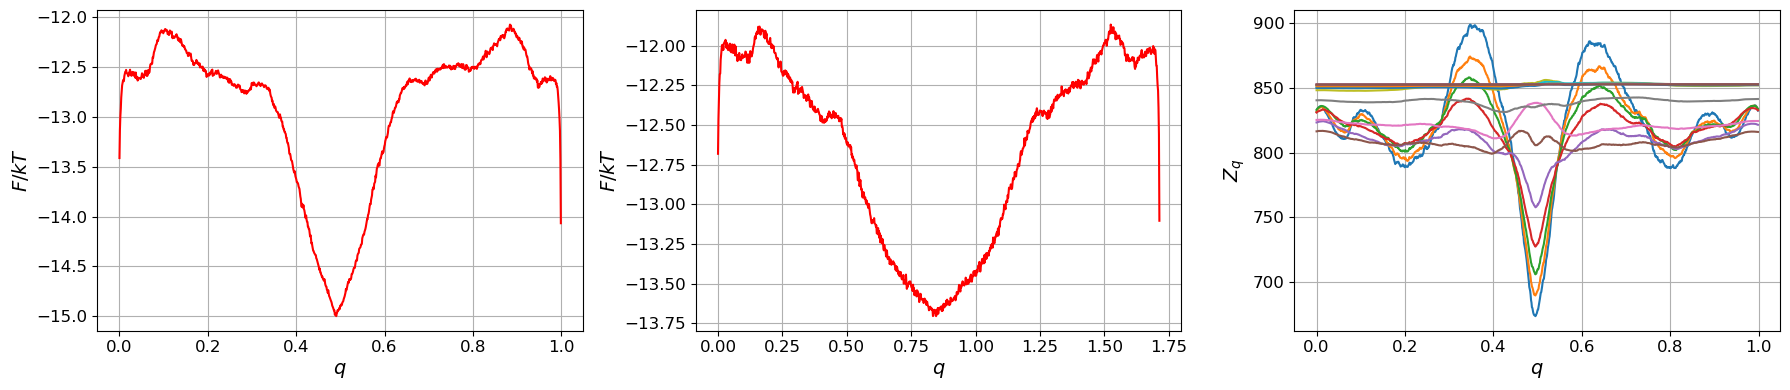

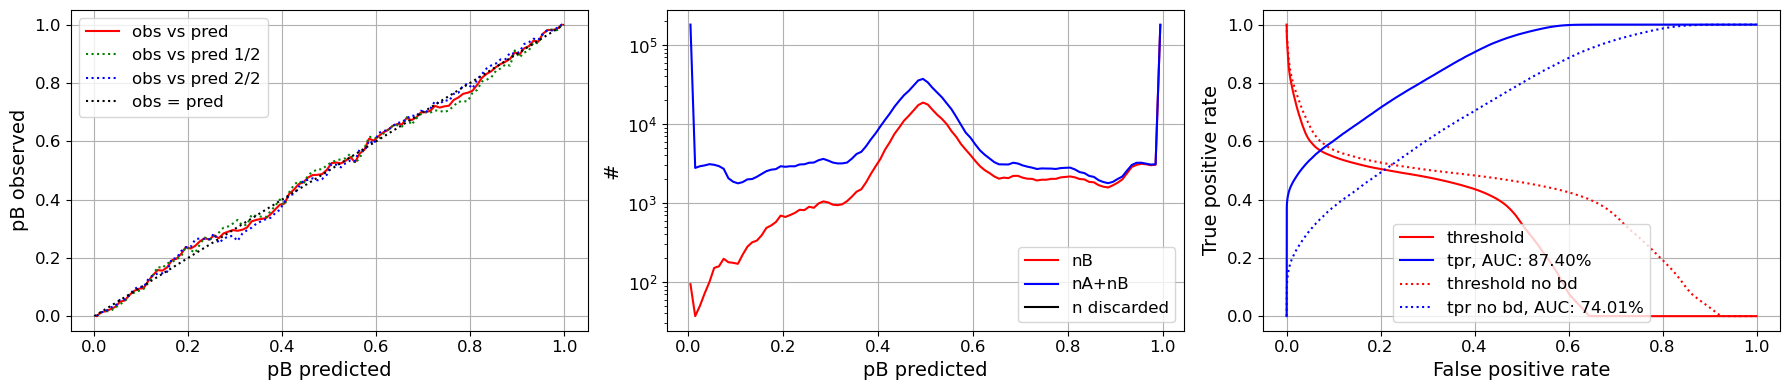

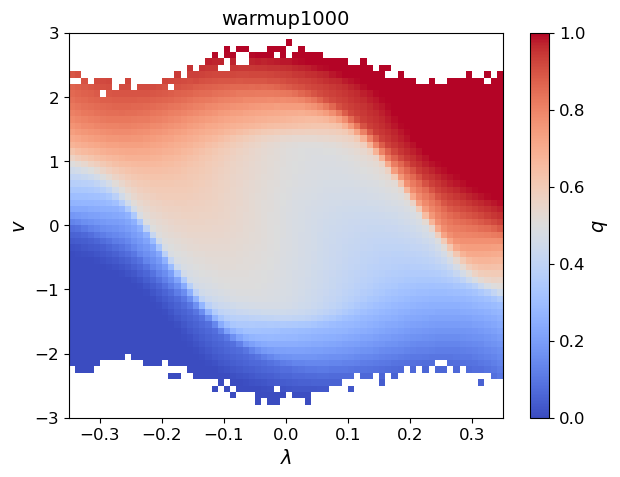

seed 99, warm-up 1000 iterations: RMS(fit - exact) per frame 0.0389
#=2000, xent=0.402009, mse=0.139962, sdzq=56.6875, dzq=168.385, dr2=1666.96, auc=0.870845, |dx|=0.0441391, time=4.00205
#=3000, xent=0.398007, mse=0.139472, sdzq=28.366, dzq=142.863, dr2=1510.7, auc=0.87284, |dx|=0.0507616, time=7.99425
#=4000, xent=0.396936, mse=0.139125, sdzq=23.609, dzq=134.932, dr2=1645.03, auc=0.87329, |dx|=0.0332501, time=11.9709
#=5000, xent=0.3995, mse=0.140628, sdzq=26.8431, dzq=102.668, dr2=1700.54, auc=0.868739, |dx|=0.0513617, time=15.9541
#=6000, xent=0.393887, mse=0.13806, sdzq=11.7214, dzq=40.0469, dr2=1736.99, auc=0.875165, |dx|=0.0429747, time=19.9122
--- figures/langevin_seeds/seed99, it6000 ---


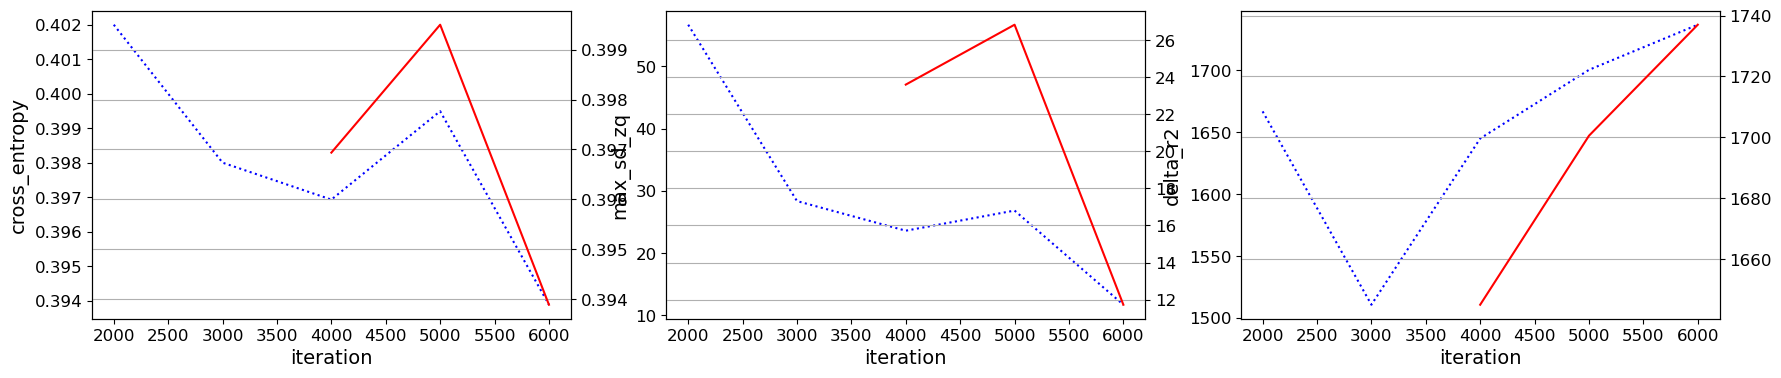

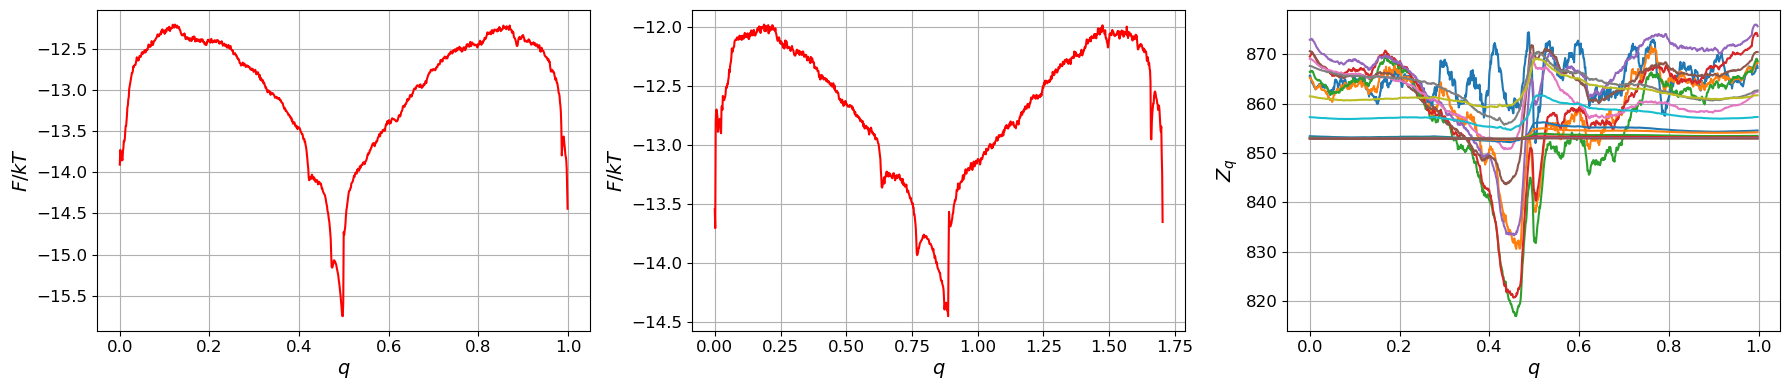

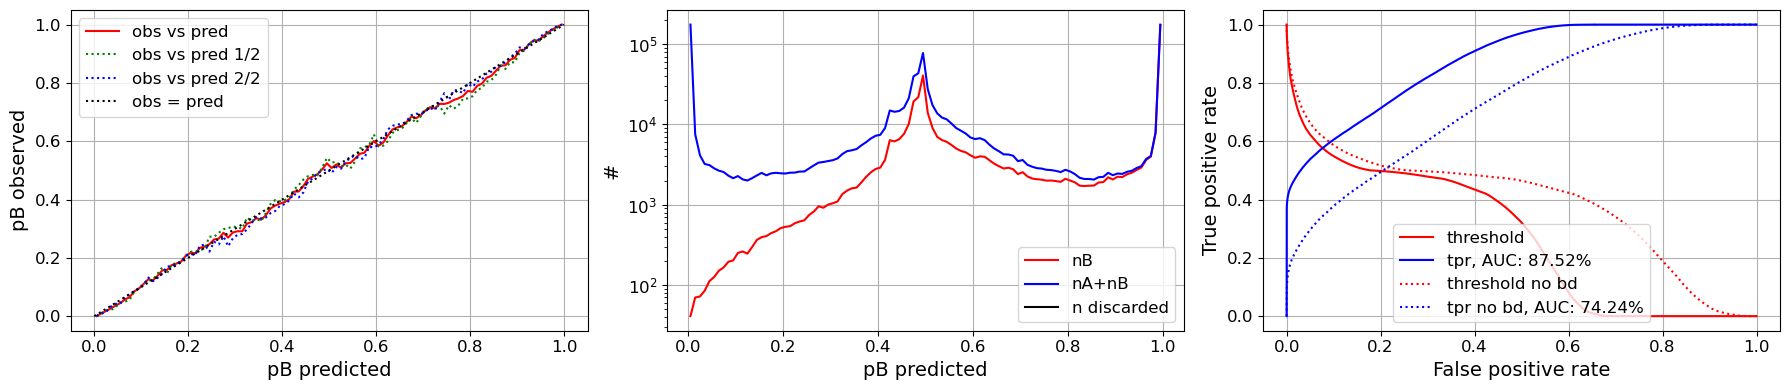

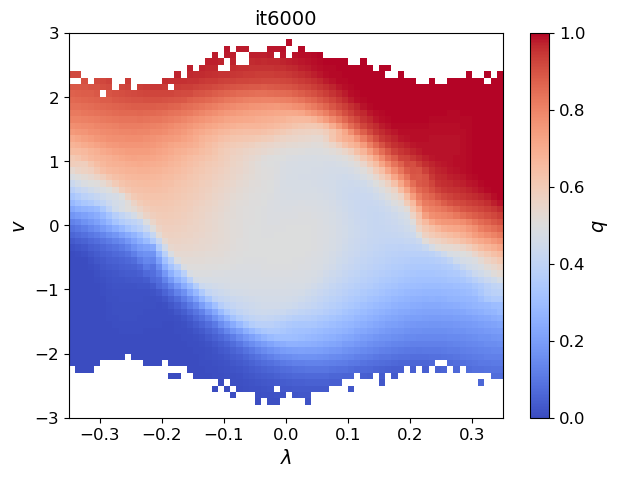

seed 99, 6000 iterations: RMS(fit - exact) per frame 0.0260, plots in figures/langevin_seeds/seed99
#=7000, xent=0.393588, mse=0.137955, sdzq=9.91846, dzq=34.7506, dr2=1724.8, auc=0.875279, |dx|=0.0174857, time=3.94211
#=8000, xent=0.396347, mse=0.138994, sdzq=26.0622, dzq=107.064, dr2=1661.05, auc=0.872383, |dx|=0.0306657, time=7.95798
#=9000, xent=0.393454, mse=0.137914, sdzq=13.9447, dzq=44.3422, dr2=1736.08, auc=0.875489, |dx|=0.02851, time=11.9624
#=10000, xent=0.403484, mse=0.142229, sdzq=94.781, dzq=249.034, dr2=1898.91, auc=0.869144, |dx|=0.0632715, time=16.004
#=11000, xent=0.394262, mse=0.138176, sdzq=15.9847, dzq=37.5107, dr2=1678.83, auc=0.874572, |dx|=0.0642355, time=20.0048
--- figures/langevin_seeds/seed99, it11000 ---


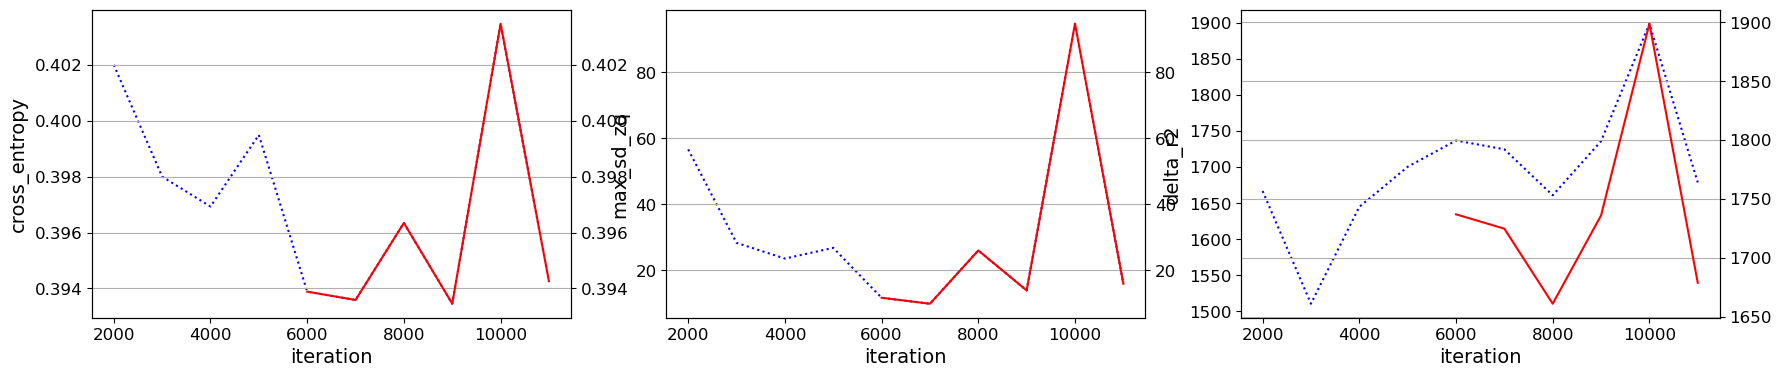

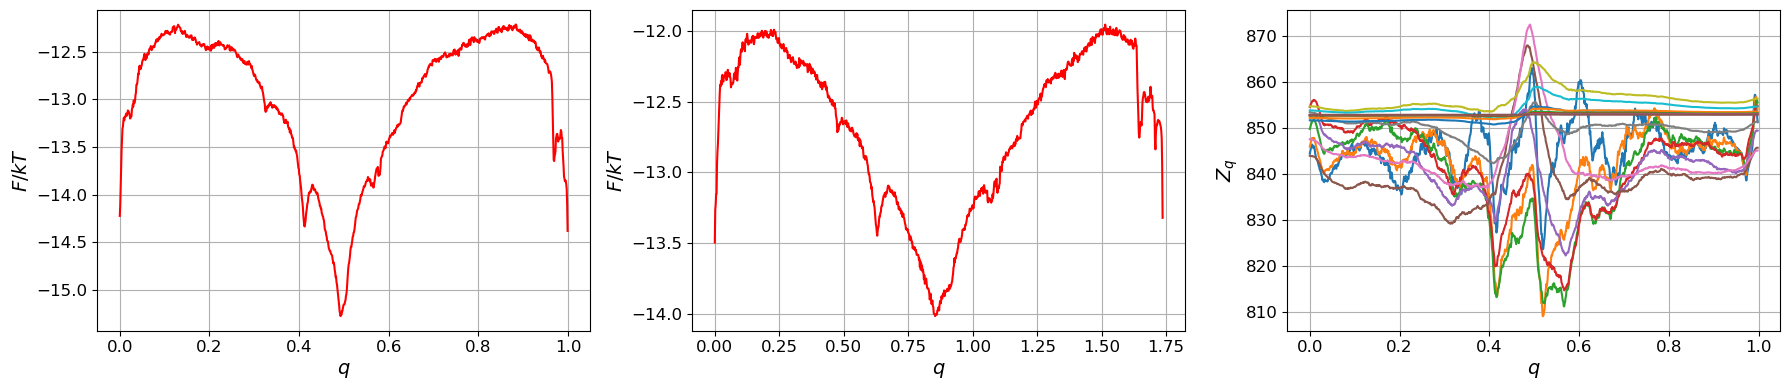

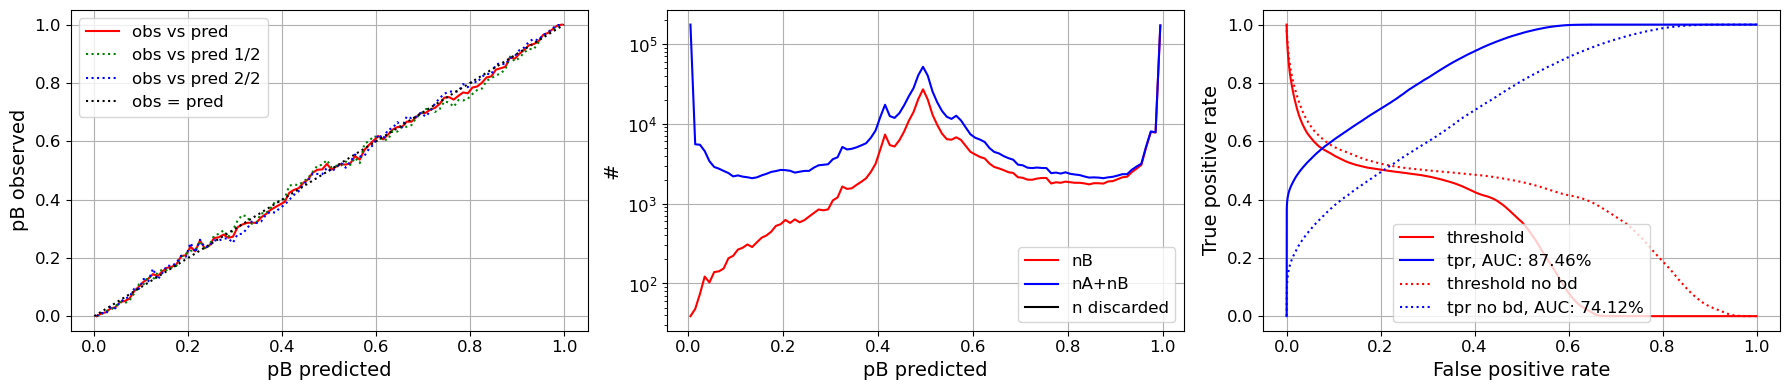

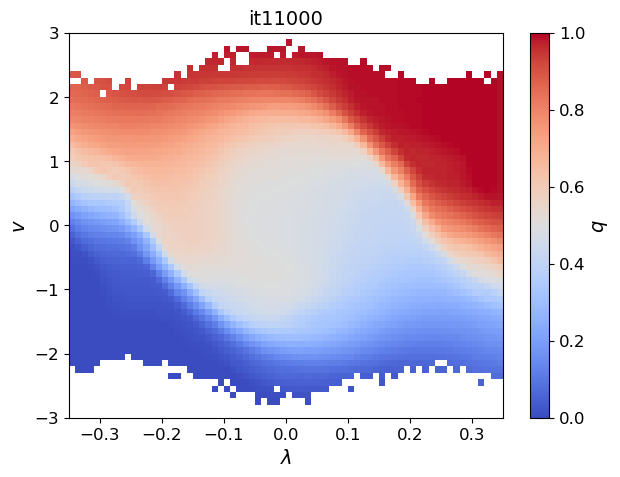

seed 99, 11000 iterations: RMS(fit - exact) per frame 0.0309, plots in figures/langevin_seeds/seed99
#=12000, xent=0.394287, mse=0.138245, sdzq=9.81851, dzq=53.4601, dr2=1727.22, auc=0.87475, |dx|=0.0254307, time=4.01982
#=13000, xent=0.395643, mse=0.138838, sdzq=22.5157, dzq=92.8385, dr2=1688.92, auc=0.873172, |dx|=0.0365455, time=8.04199
#=14000, xent=0.406512, mse=0.142049, sdzq=38.9284, dzq=137.744, dr2=1734.4, auc=0.870298, |dx|=0.0661436, time=12.0619
#=15000, xent=0.398718, mse=0.139306, sdzq=24.203, dzq=122.607, dr2=1557.43, auc=0.873277, |dx|=0.0598061, time=16.0523
#=16000, xent=0.394963, mse=0.138565, sdzq=12.0827, dzq=44.1612, dr2=1702.16, auc=0.875273, |dx|=0.0429657, time=20.0973
--- figures/langevin_seeds/seed99, it16000 ---


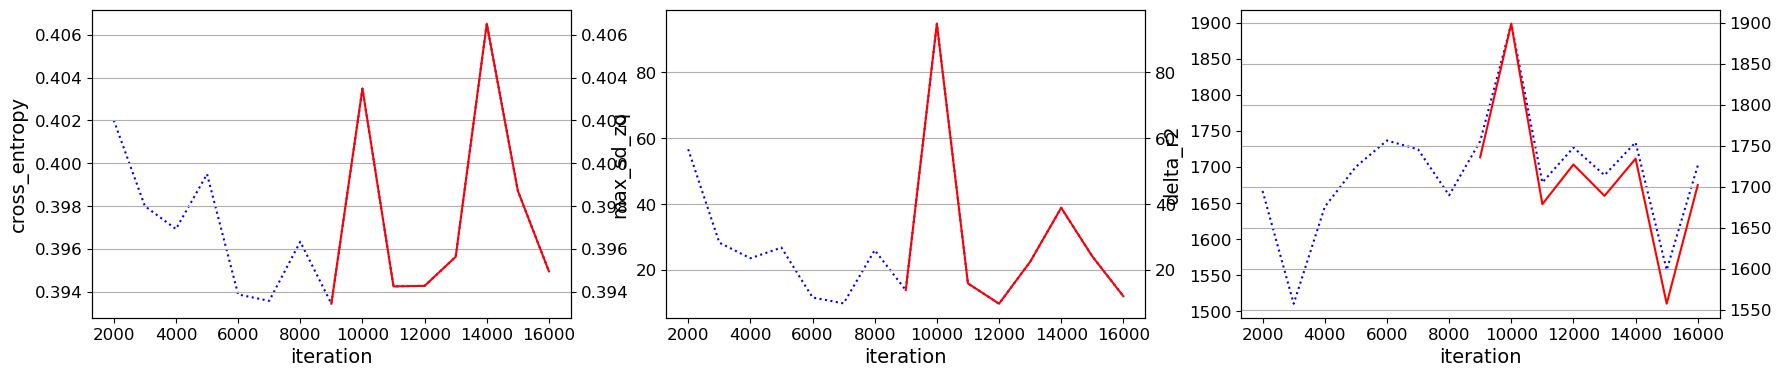

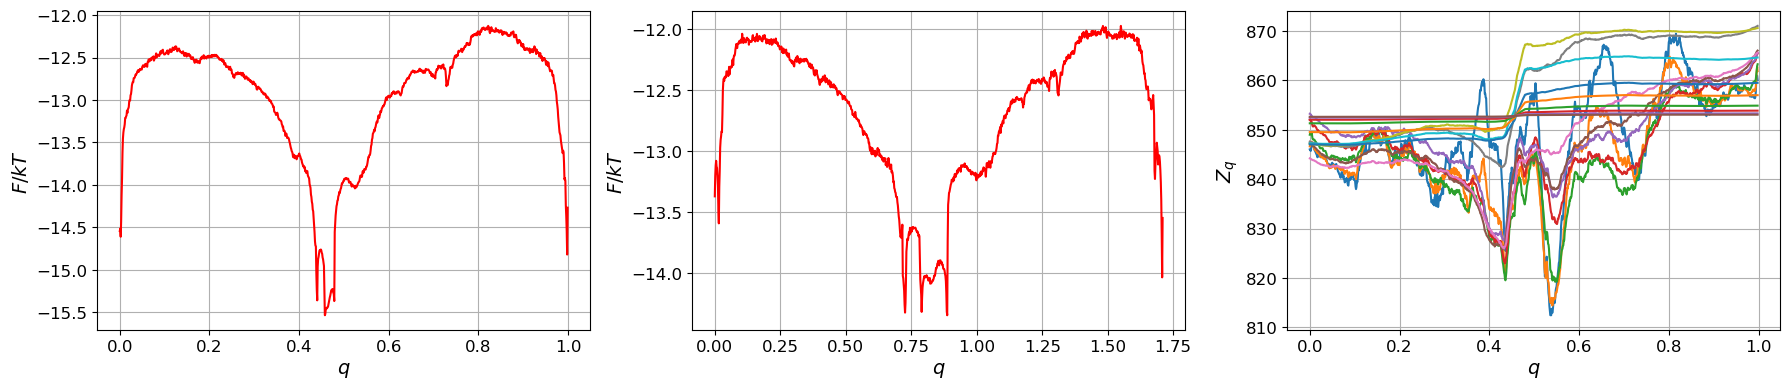

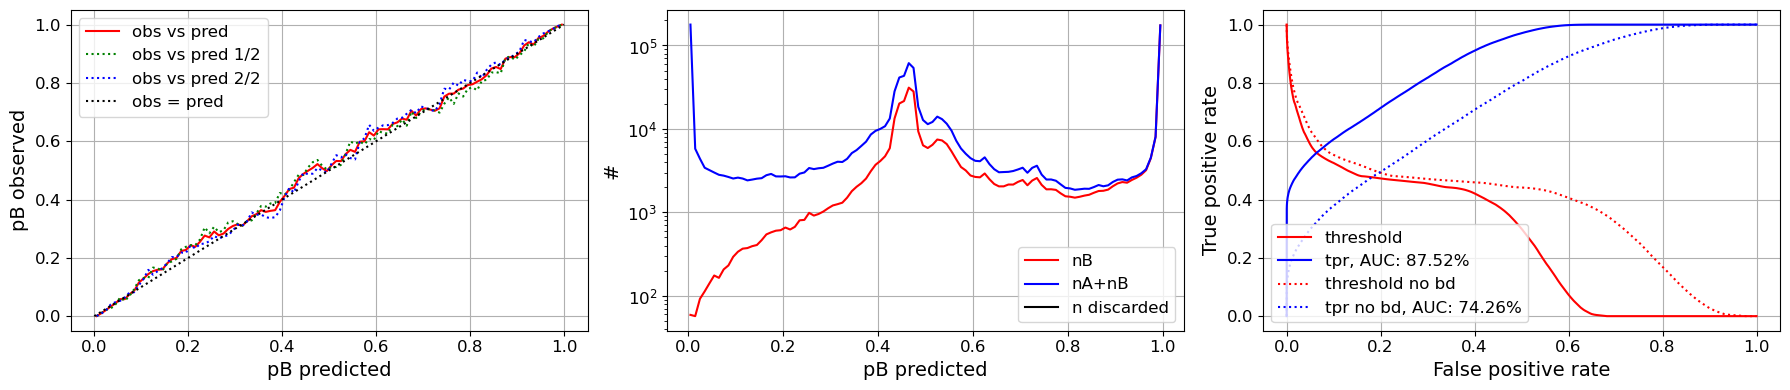

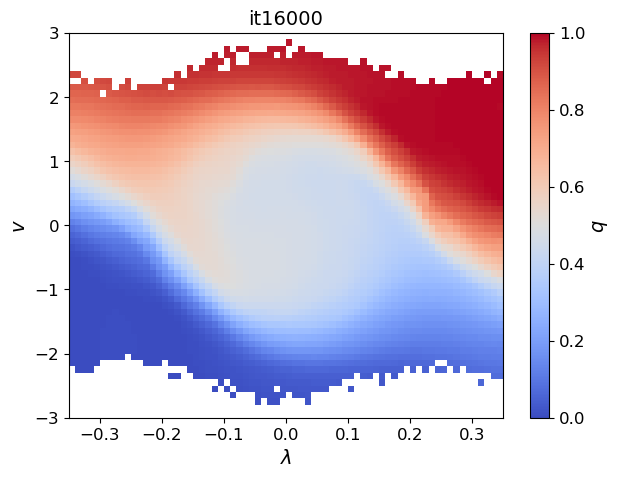

seed 99, 16000 iterations: RMS(fit - exact) per frame 0.0351, plots in figures/langevin_seeds/seed99
seed 99: RMS(fit - exact) per frame 0.0351


In [16]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [99]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds'

ENVELOPE = 0.01                       # envelope_scale for the main run
GAMMA = 0.                        # regularization strength for the main run
# Optional warm-up: the first WARMUP_ITER iterations of every seed use their own envelope, gamma
# and CV choice, then the main settings take over. WARMUP_ITER = 0 switches it off.
WARMUP_ITER = 1000
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = 0.
WARMUP_CV = None                   # None: random CV as in the main run; 0: lambda only; 1: v only
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); hold it off so every figure can be saved,
    # then show them all inline at the end
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100)
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100)
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100)
    finally:
        plt.show = show
    print(f'--- {folder}, {tag} ---')
    plt.show()                     # display (and close) the four figures
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    if WARMUP_ITER > 0:
        optimalrcs.envelope_scale = WARMUP_ENVELOPE
        comp_y = (lambda: Y[:, np.random.randint(2)]) if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV])
        q.fit_transform(comp_y, gamma=WARMUP_GAMMA, ny=6, max_iter=WARMUP_ITER, print_step=WARMUP_ITER,
                        save_min_delta_zq=False, lazy_basis=True)
        r = save_plots(q, folder, f'warmup{WARMUP_ITER}')
        print(f'seed {seed}, warm-up {WARMUP_ITER} iterations: RMS(fit - exact) per frame '
              f'{np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}', flush=True)
    optimalrcs.envelope_scale = ENVELOPE
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: Y[:, np.random.randint(2)],
            gamma=GAMMA,
            ny=6,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{WARMUP_ITER + done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {WARMUP_ITER + done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Final RMS per seed (the plots of every chunk are shown above)
for seed, r in results.items():
    print(f'seed {seed}: RMS(fit - exact) per frame {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}')

#=2000, xent=0.400857, mse=0.139549, sdzq=57.29, dzq=181.931, dr2=1911.67, auc=0.872647, |dx|=0.208129, time=23.4903
--- figures/langevin_hist_seeds/seed99, warmup2000 ---


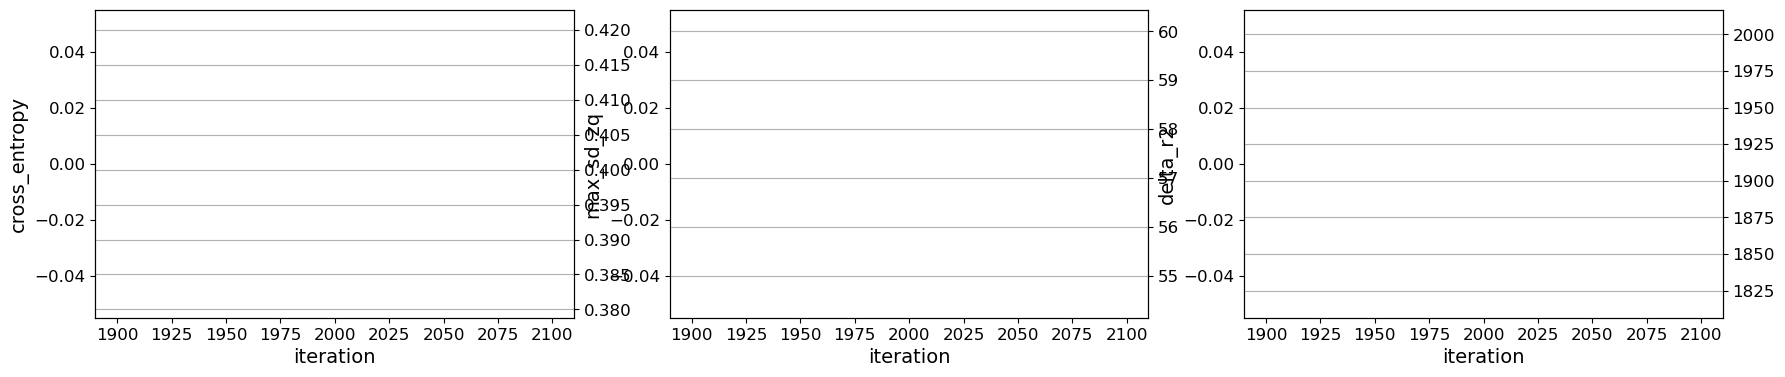

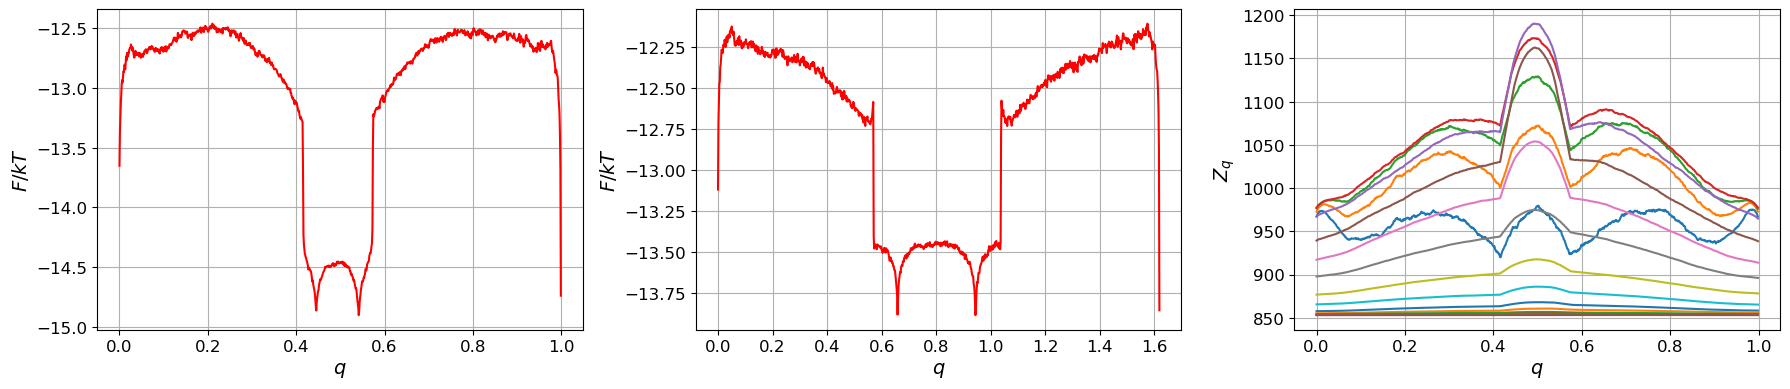

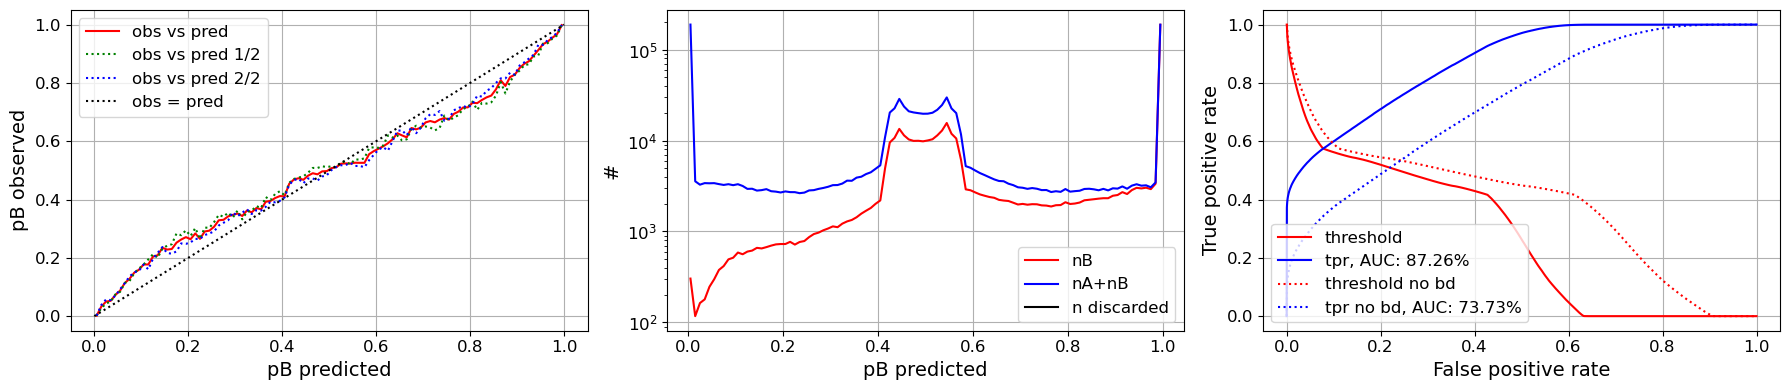

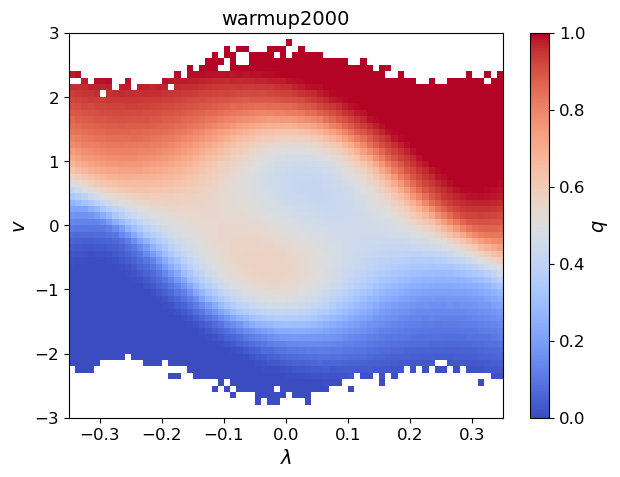

seed 99, warm-up 2000 iterations: RMS(fit - exact) per frame 0.0521
#=3000, xent=0.395973, mse=0.138454, sdzq=35.8532, dzq=80.4453, dr2=1875.31, auc=0.875283, |dx|=0.0284299, time=11.3376
#=4000, xent=0.395963, mse=0.138418, sdzq=35.7632, dzq=79.9519, dr2=1871.86, auc=0.875352, |dx|=0.00217614, time=23.3731
#=5000, xent=0.395709, mse=0.138389, sdzq=35.5902, dzq=79.7737, dr2=1871.27, auc=0.875389, |dx|=0.0014335, time=35.3415
#=6000, xent=0.395689, mse=0.13838, sdzq=35.3361, dzq=79.2459, dr2=1869.35, auc=0.875375, |dx|=0.000969573, time=46.6911
#=7000, xent=0.39571, mse=0.138374, sdzq=35.4317, dzq=79.3926, dr2=1869.66, auc=0.875393, |dx|=0.000957424, time=58.6213
--- figures/langevin_hist_seeds/seed99, it7000 ---


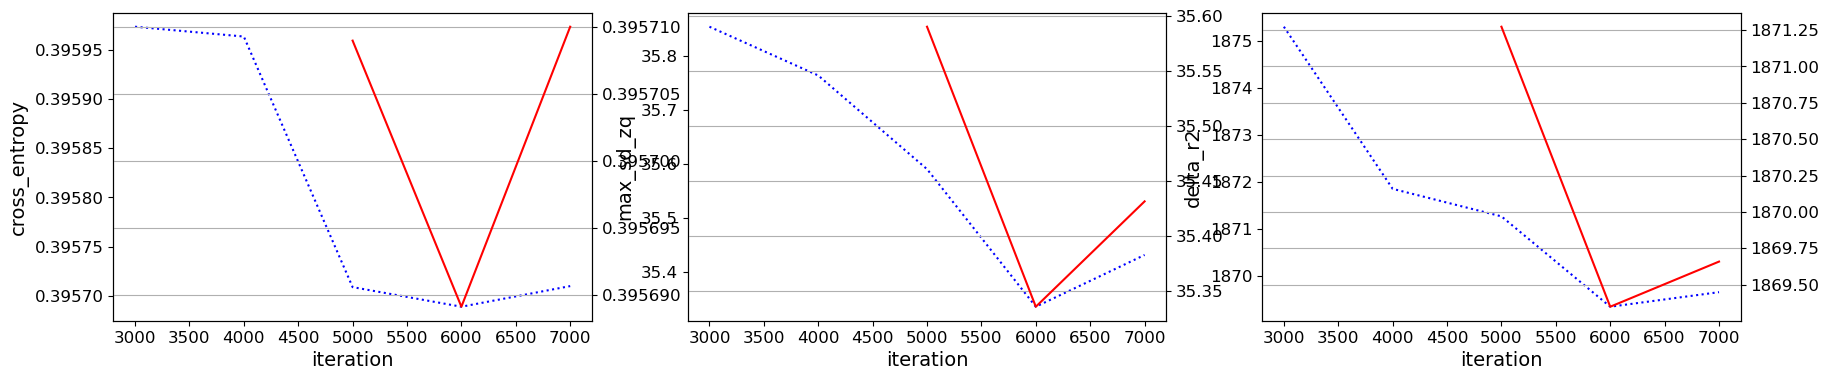

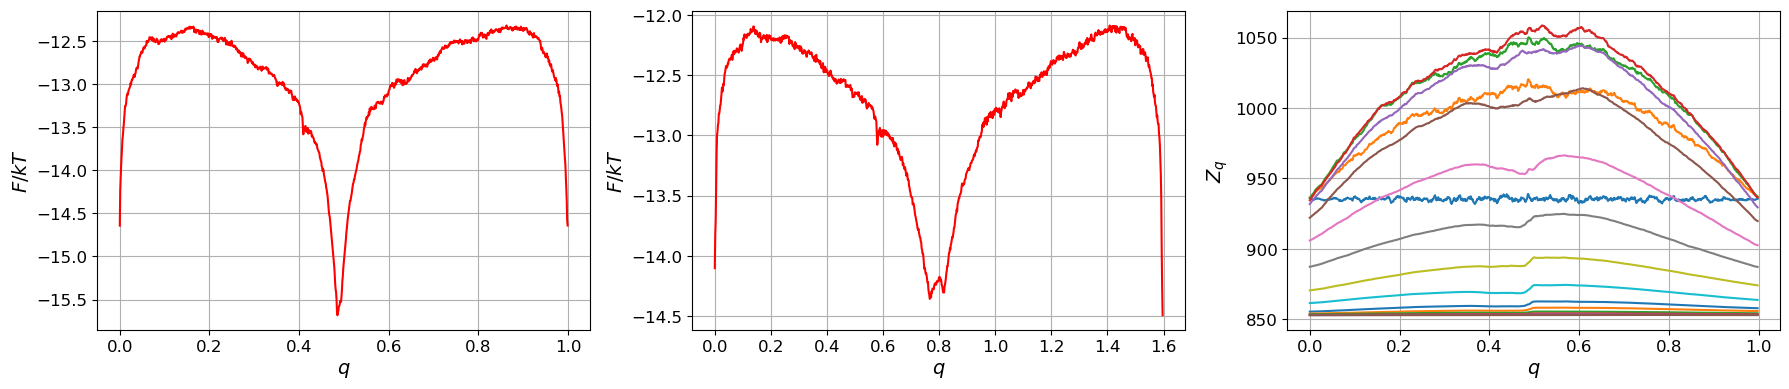

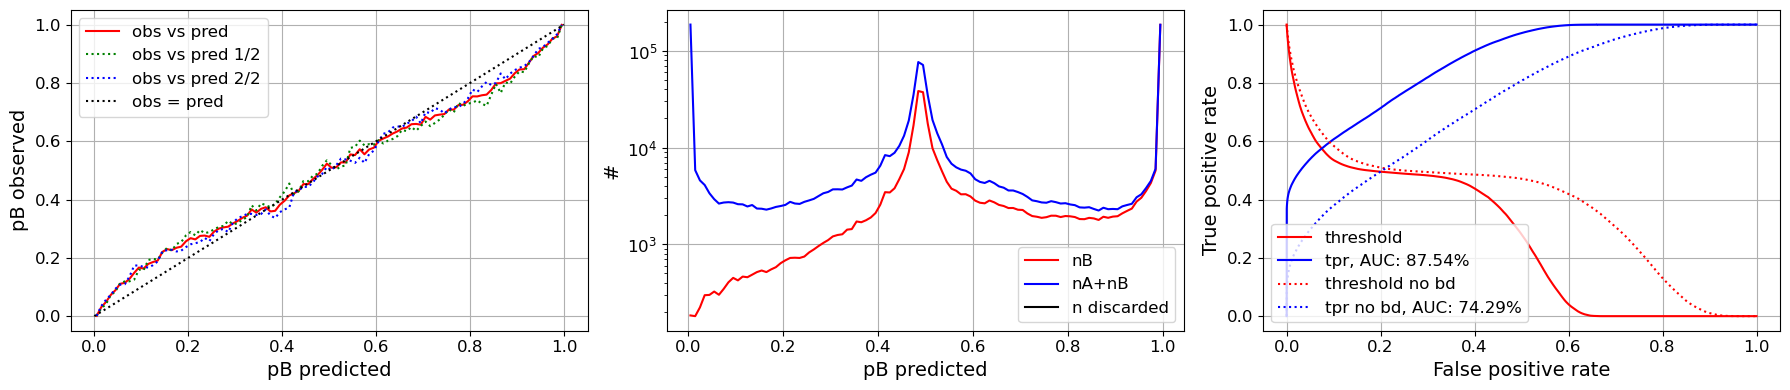

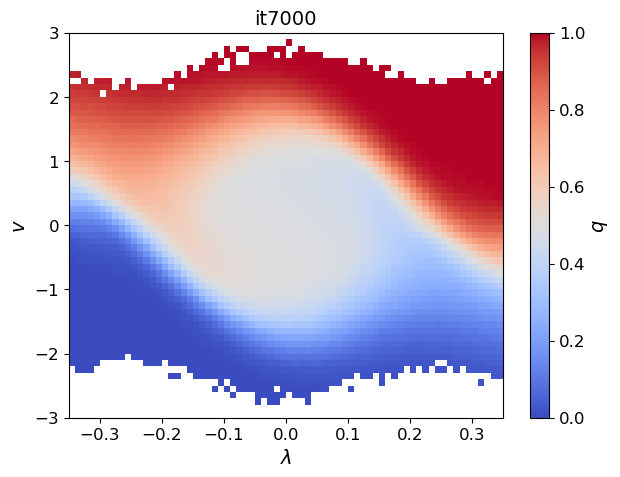

seed 99, 7000 iterations: RMS(fit - exact) per frame 0.0340, plots in figures/langevin_hist_seeds/seed99
#=8000, xent=0.395685, mse=0.138373, sdzq=35.4576, dzq=79.4995, dr2=1869.93, auc=0.875407, |dx|=0.000565174, time=11.9294
#=9000, xent=0.395633, mse=0.138357, sdzq=35.4382, dzq=79.3573, dr2=1868.46, auc=0.875438, |dx|=0.000725551, time=23.2387
#=10000, xent=0.395626, mse=0.13835, sdzq=35.3894, dzq=79.2555, dr2=1867.31, auc=0.875443, |dx|=0.000582806, time=35.0993
#=11000, xent=0.395664, mse=0.138352, sdzq=35.2672, dzq=79.0427, dr2=1867.52, auc=0.875425, |dx|=0.00044988, time=47.0121
#=12000, xent=0.395594, mse=0.138346, sdzq=35.2988, dzq=79.0395, dr2=1866.78, auc=0.875445, |dx|=0.000486762, time=54.1892
--- figures/langevin_hist_seeds/seed99, it12000 ---


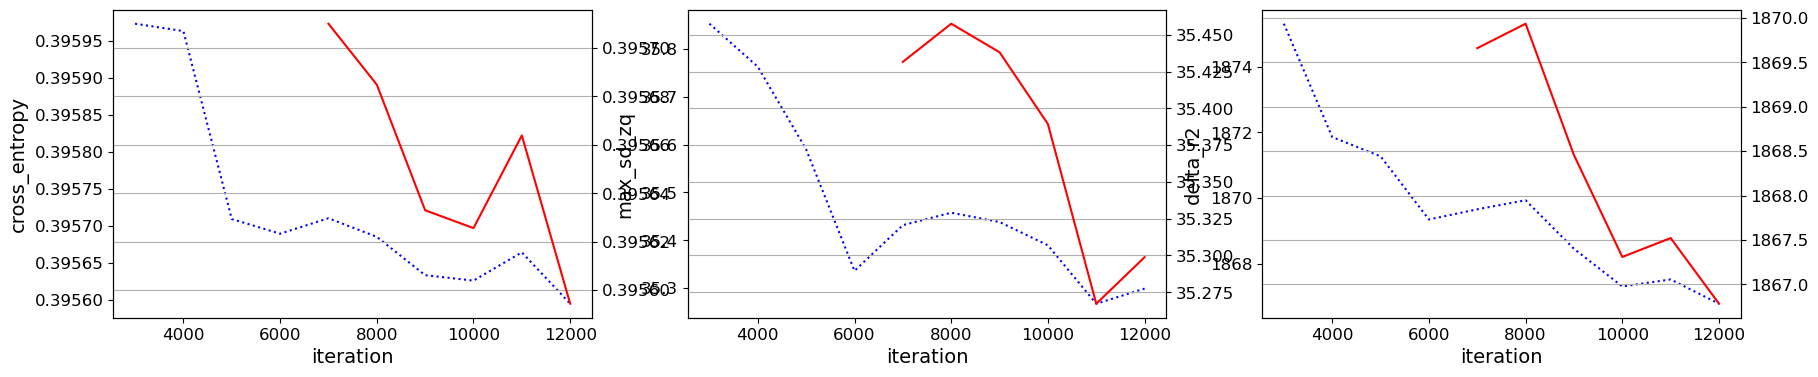

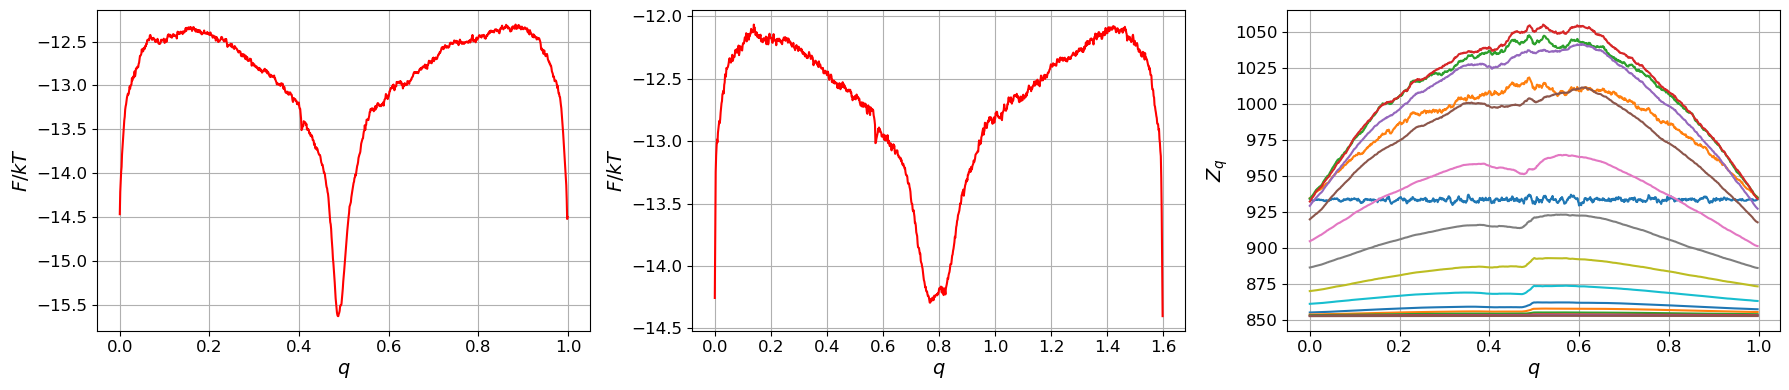

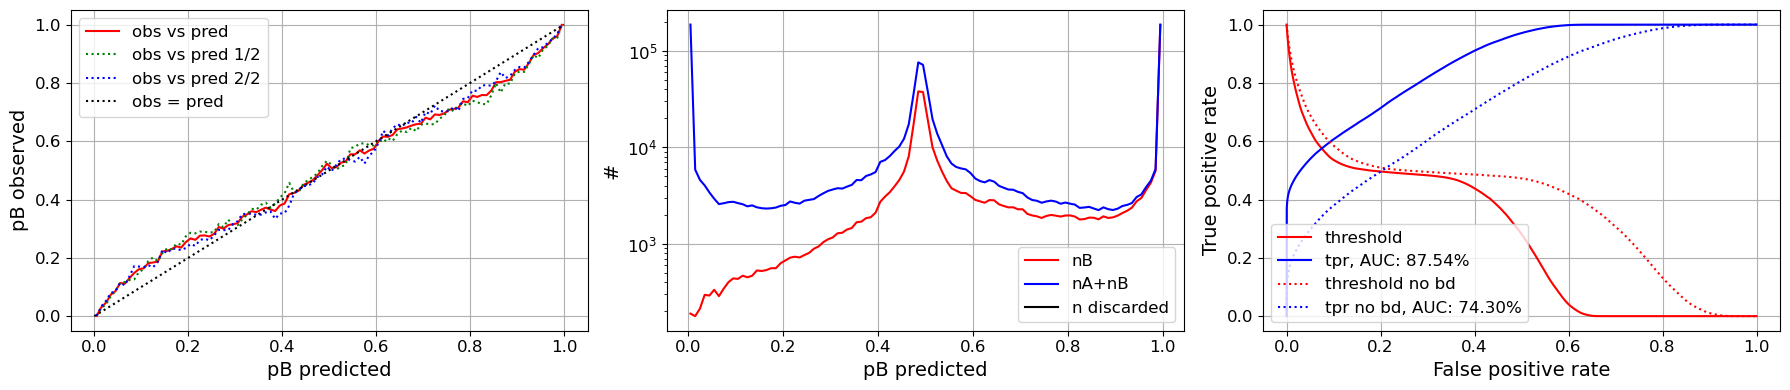

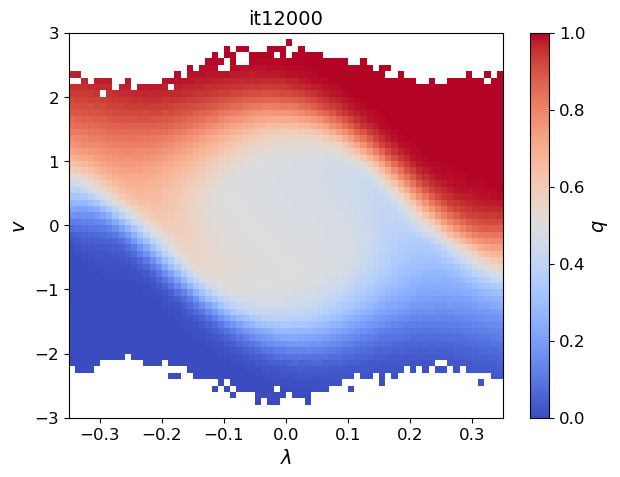

seed 99, 12000 iterations: RMS(fit - exact) per frame 0.0334, plots in figures/langevin_hist_seeds/seed99
#=13000, xent=0.395568, mse=0.138338, sdzq=35.3755, dzq=79.1322, dr2=1866.33, auc=0.875463, |dx|=0.00039464, time=5.85989
#=14000, xent=0.395563, mse=0.138331, sdzq=35.2465, dzq=78.9281, dr2=1865.91, auc=0.875476, |dx|=0.000425076, time=11.3597
#=15000, xent=0.395585, mse=0.138337, sdzq=35.273, dzq=79.0927, dr2=1866.5, auc=0.875474, |dx|=0.000654412, time=16.4447
#=16000, xent=0.395516, mse=0.138329, sdzq=35.2463, dzq=78.9312, dr2=1865.04, auc=0.875467, |dx|=0.000563524, time=22.3097
#=17000, xent=0.395526, mse=0.13833, sdzq=35.3357, dzq=79.0701, dr2=1864.8, auc=0.875472, |dx|=0.000330839, time=28.1671
--- figures/langevin_hist_seeds/seed99, it17000 ---


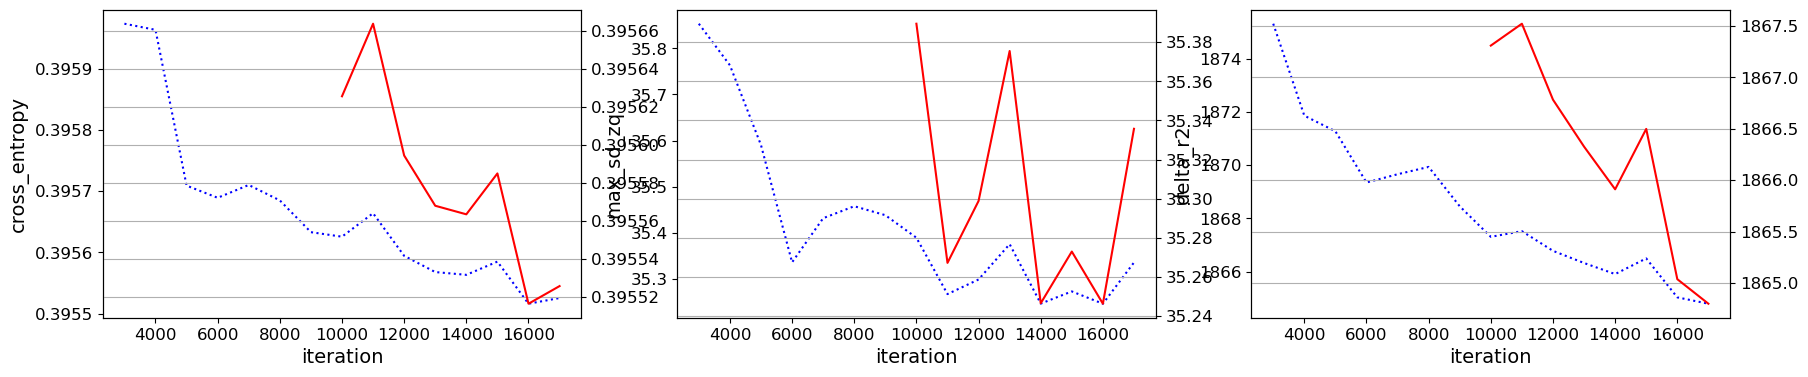

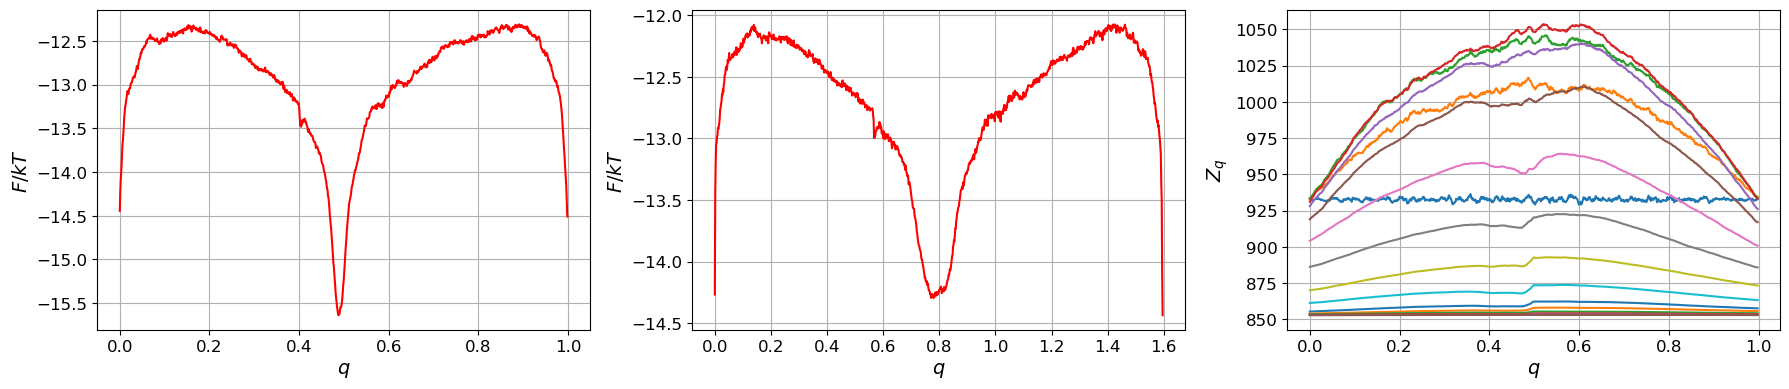

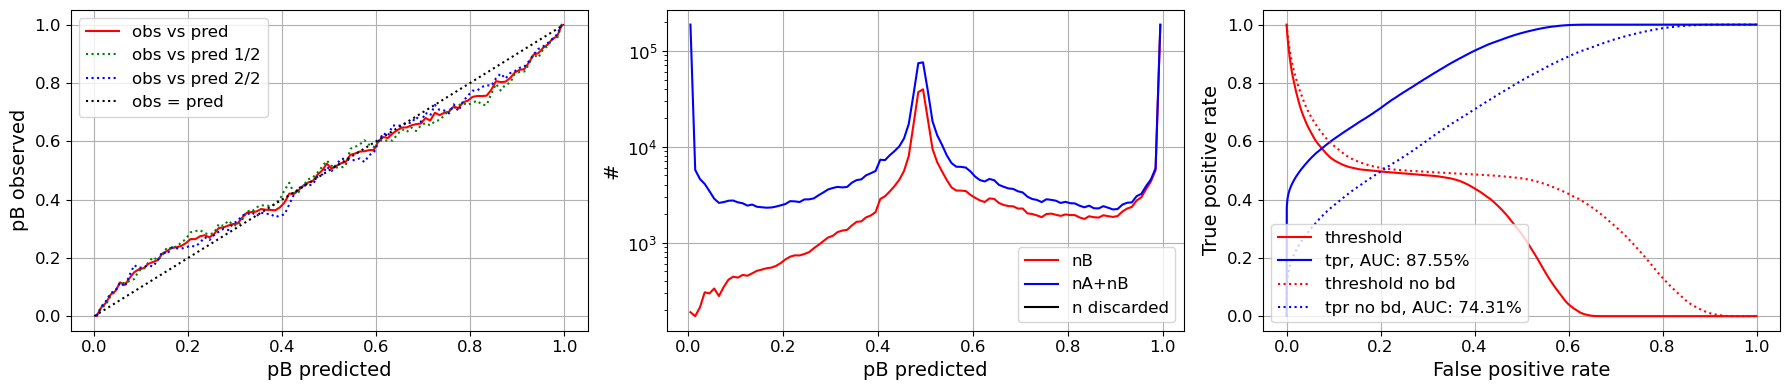

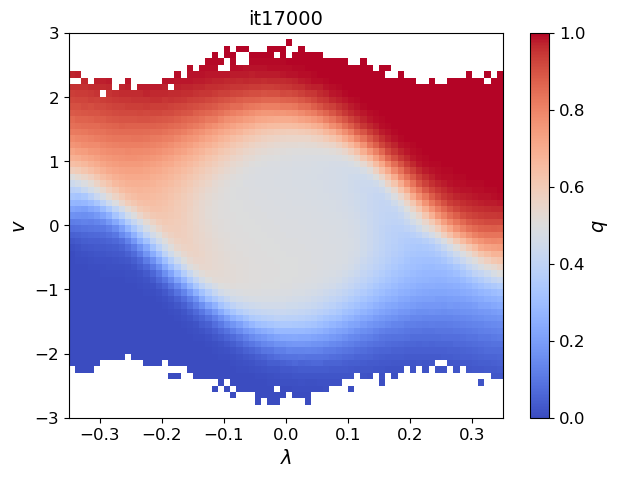

seed 99, 17000 iterations: RMS(fit - exact) per frame 0.0332, plots in figures/langevin_hist_seeds/seed99
seed 99: RMS(fit - exact) per frame 0.0332


In [14]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [99]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_hist_seeds'

ENVELOPE = 0.01                       # envelope_scale for the main run
GAMMA = 0.                        # regularization strength for the main run
# Optional warm-up: the first WARMUP_ITER iterations of every seed use their own envelope, gamma
# and CV choice, then the main settings take over. WARMUP_ITER = 0 switches it off.
WARMUP_ITER = 2000
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = 0.
WARMUP_CV = 0                   # None: random CV as in the main run; 0: lambda only; 1: v only
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity
history=[0,1]
yr_type=['y(t-d),y(t)']

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); hold it off so every figure can be saved,
    # then show them all inline at the end
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100)
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100)
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100)
    finally:
        plt.show = show
    print(f'--- {folder}, {tag} ---')
    plt.show()                     # display (and close) the four figures
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    if WARMUP_ITER > 0:
        optimalrcs.envelope_scale = WARMUP_ENVELOPE
        comp_y = (lambda: Y[:, np.random.randint(2)]) if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV])
        q.fit_transform(lambda: lam,
                        #comp_y,
                        gamma=WARMUP_GAMMA, 
                        #ny=6, 
                        max_iter=WARMUP_ITER, print_step=WARMUP_ITER,
                        history_delta_t=history,
                        history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000,
                        save_min_delta_zq=False, 
                        lazy_basis=True
                       )
        r = save_plots(q, folder, f'warmup{WARMUP_ITER}')
        print(f'seed {seed}, warm-up {WARMUP_ITER} iterations: RMS(fit - exact) per frame '
              f'{np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}', flush=True)
    optimalrcs.envelope_scale = ENVELOPE
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: lam,
            #lambda: Y[:, np.random.randint(2)],
            gamma=GAMMA,
            #ny=6,
            history_delta_t=history,
            history_type=yr_type, history_shift_type='r(t)',
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
           lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{WARMUP_ITER + done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {WARMUP_ITER + done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Final RMS per seed (the plots of every chunk are shown above)
for seed, r in results.items():
    print(f'seed {seed}: RMS(fit - exact) per frame {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}')

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

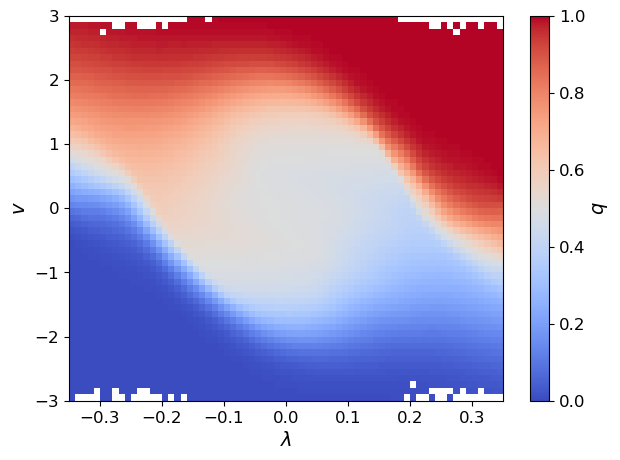

In [6]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [7]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))